<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/E_Commerce_Sales_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

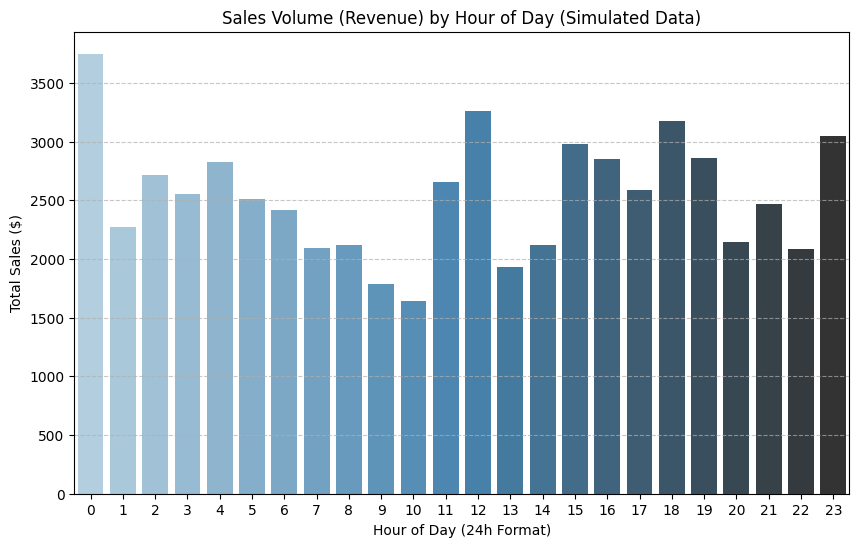

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate dummy e-commerce sales data since 'df' was only defined in markdown text
np.random.seed(42)
n_samples = 1000

data = {
    'Hour': np.random.randint(0, 24, size=n_samples),
    'TotalSales': np.random.exponential(scale=50, size=n_samples) + np.random.normal(loc=10, scale=2, size=n_samples)
}
df = pd.DataFrame(data)

# Group by hour and calculate total sales volume
hourly_sales = df.groupby('Hour')['TotalSales'].sum().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=hourly_sales, x='Hour', y='TotalSales', hue='Hour', palette='Blues_d', legend=False)
plt.title('Sales Volume (Revenue) by Hour of Day (Simulated Data)')
plt.xlabel('Hour of Day (24h Format)')
plt.ylabel('Total Sales ($)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Identify the top 3 hours with the highest revenue
top_3_hours = hourly_sales.sort_values(by='TotalSales', ascending=False).head(3)

print("Top 3 Hours with Highest Revenue:")
for index, row in top_3_hours.iterrows():
    print(f"Hour: {int(row['Hour'])}:00 - Total Sales: ${row['TotalSales']:.2f}")

Top 3 Hours with Highest Revenue:
Hour: 0:00 - Total Sales: $3747.87
Hour: 12:00 - Total Sales: $3262.96
Hour: 18:00 - Total Sales: $3177.35


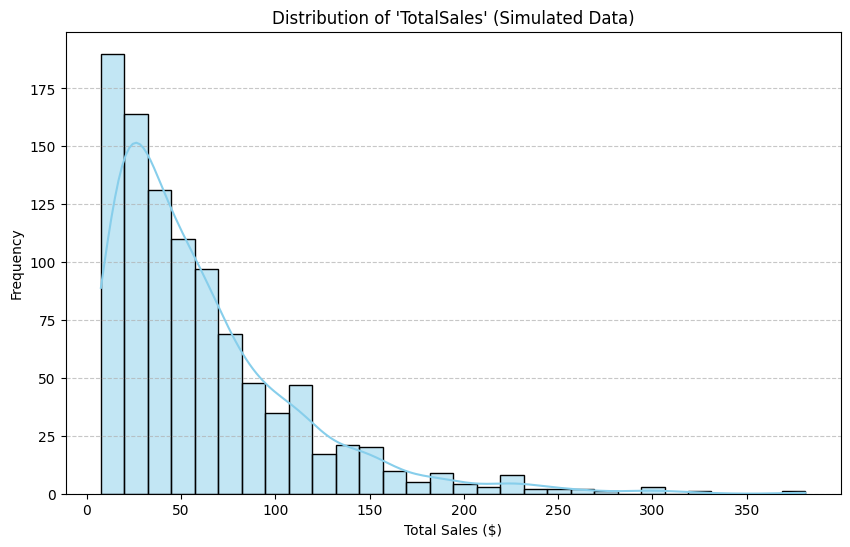

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['TotalSales'], kde=True, color='skyblue', bins=30)
plt.title("Distribution of 'TotalSales' (Simulated Data)")
plt.xlabel('Total Sales ($)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

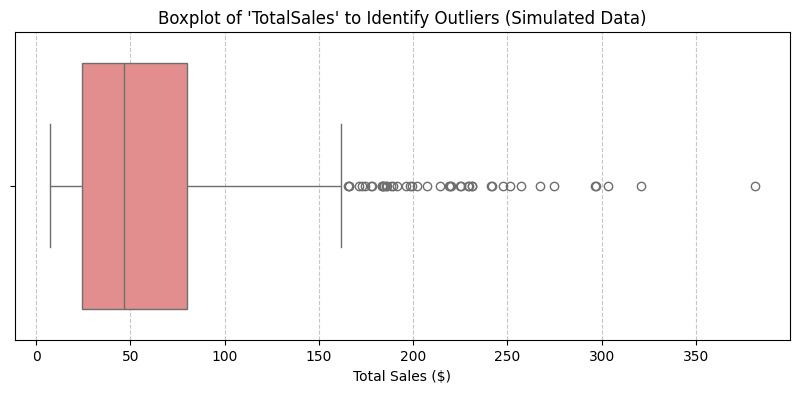

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['TotalSales'], color='lightcoral')
plt.title("Boxplot of 'TotalSales' to Identify Outliers (Simulated Data)")
plt.xlabel('Total Sales ($)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# Calculate the 95th percentile of TotalSales
threshold_95 = df['TotalSales'].quantile(0.95)

# Filter transactions above the 95th percentile
outliers_df = df[df['TotalSales'] > threshold_95].sort_values(by='TotalSales', ascending=False)

print(f"95th Percentile Threshold: ${threshold_95:.2f}")
print(f"Number of transactions above the 95th percentile: {len(outliers_df)}")

# Display the top 10 highest-value outlier transactions
display(outliers_df.head(10))

95th Percentile Threshold: $159.56
Number of transactions above the 95th percentile: 50


,Hour,TotalSales
770,18,381.179649
360,17,321.106342
515,0,303.150686
153,12,297.184515
639,5,296.707059
410,9,274.737063
922,12,267.186623
944,5,257.004312
970,23,251.218143
897,13,247.501097


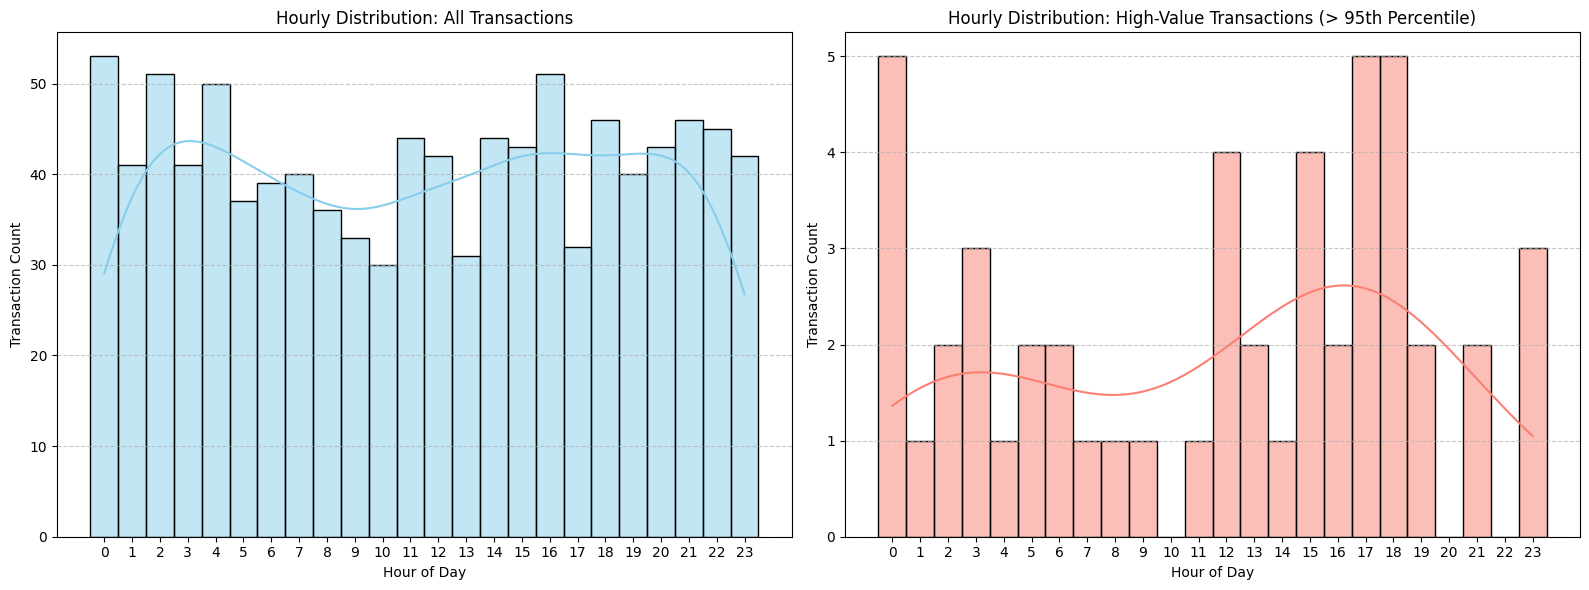

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create a column to categorize transactions
df['IsHighValue'] = df['TotalSales'] > threshold_95

# Setup the figure for side-by-side distribution plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

# Plot 1: All Transactions Hourly Distribution
sns.histplot(data=df, x='Hour', bins=24, discrete=True, color='skyblue', kde=True, ax=axes[0])
axes[0].set_title('Hourly Distribution: All Transactions')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Transaction Count')
axes[0].set_xticks(range(0, 24))
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: High-Value Transactions Hourly Distribution
sns.histplot(data=outliers_df, x='Hour', bins=24, discrete=True, color='salmon', kde=True, ax=axes[1])
axes[1].set_title('Hourly Distribution: High-Value Transactions (> 95th Percentile)')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Transaction Count')
axes[1].set_xticks(range(0, 24))
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

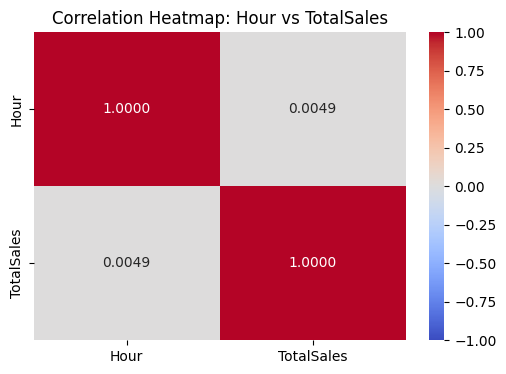

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix between Hour and TotalSales
correlation_matrix = df[['Hour', 'TotalSales']].corr()

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".4f")
plt.title('Correlation Heatmap: Hour vs TotalSales')
plt.show()

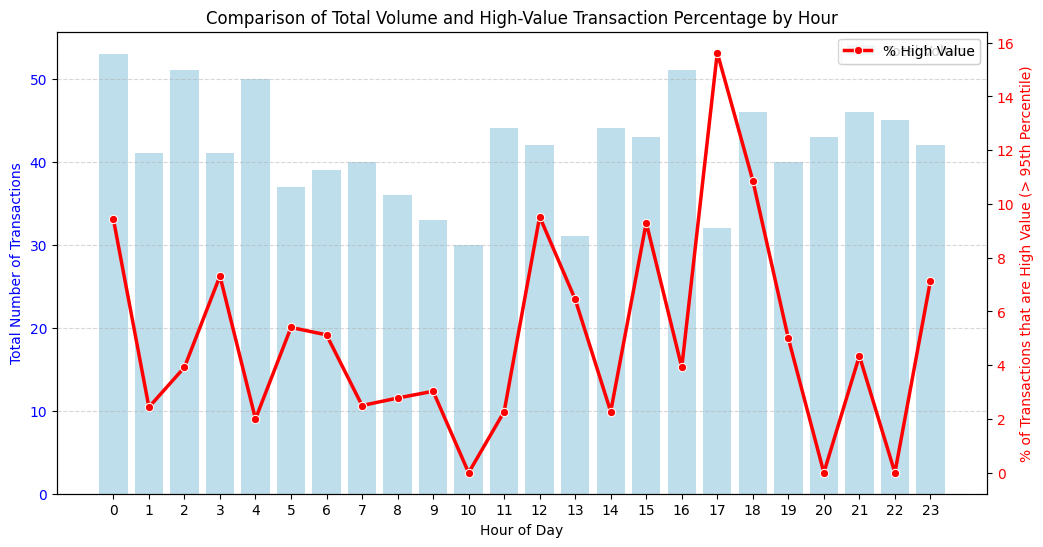

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Count total transactions per hour
total_counts = df.groupby('Hour').size().reset_index(name='Total_Count')

# Count high-value transactions per hour
high_value_counts = outliers_df.groupby('Hour').size().reset_index(name='High_Value_Count')

# Merge and calculate the ratio/percentage
hourly_ratio = pd.merge(total_counts, high_value_counts, on='Hour', how='left').fillna(0)
hourly_ratio['High_Value_Percentage'] = (hourly_ratio['High_Value_Count'] / hourly_ratio['Total_Count']) * 100

# Create dual-axis plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar plot for total volume
sns.barplot(data=hourly_ratio, x='Hour', y='Total_Count', color='skyblue', alpha=0.6, label='Total Volume', ax=ax1)
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Total Number of Transactions', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Line plot for high-value ratio
ax2 = ax1.twinx()
sns.lineplot(data=hourly_ratio, x='Hour', y='High_Value_Percentage', color='red', marker='o', linewidth=2.5, label='% High Value', ax=ax2)
ax2.set_ylabel('% of Transactions that are High Value (> 95th Percentile)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Comparison of Total Volume and High-Value Transaction Percentage by Hour')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Create a pivot table of High_Value_Percentage by Hour
pivot_high_value = hourly_ratio.pivot_table(
    values='High_Value_Percentage',
    index='Hour'
)

# Display the pivot table styled with a gradient
display(pivot_high_value.style.background_gradient(cmap='YlOrRd').format("{:.2f}%"))

,High_Value_Percentage
Hour,
0,9.43%
1,2.44%
2,3.92%
3,7.32%
4,2.00%
5,5.41%
6,5.13%
7,2.50%
8,2.78%


In [ ]:
# Filter for hours with zero high-value transactions
zero_high_value_hours = hourly_ratio[hourly_ratio['High_Value_Count'] == 0][['Hour', 'Total_Count']]

print("Hours with 0 High-Value Transactions:")
display(zero_high_value_hours.reset_index(drop=True))

Hours with 0 High-Value Transactions:


,Hour,Total_Count
0,10,30
1,20,43
2,22,45


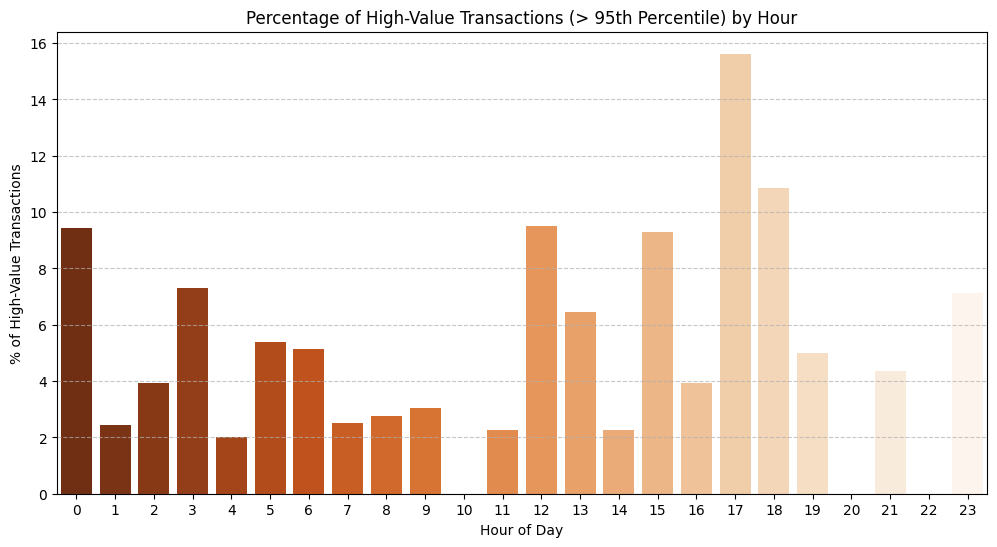

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(data=hourly_ratio, x='Hour', y='High_Value_Percentage', hue='Hour', palette='Oranges_r', legend=False)

plt.title('Percentage of High-Value Transactions (> 95th Percentile) by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('% of High-Value Transactions')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import scipy.stats as stats

# Extract sales data for Hour 17 and Hour 10
sales_hour_17 = df[df['Hour'] == 17]['TotalSales']
sales_hour_10 = df[df['Hour'] == 10]['TotalSales']

# Calculate basic statistics
mean_17, median_17 = sales_hour_17.mean(), sales_hour_17.median()
mean_10, median_10 = sales_hour_10.mean(), sales_hour_10.median()

print(f"Hour 17 (N={len(sales_hour_17)}): Mean = ${mean_17:.2f}, Median = ${median_17:.2f}")
print(f"Hour 10 (N={len(sales_hour_10)}): Mean = ${mean_10:.2f}, Median = ${median_10:.2f}\n")

# Perform Mann-Whitney U Test (Non-parametric, suitable for skewed data)
mwu_stat, mwu_p = stats.mannwhitneyu(sales_hour_17, sales_hour_10, alternative='two-sided')
print("--- Mann-Whitney U Test ---")
print(f"U-statistic: {mwu_stat:.2f}")
print(f"p-value: {mwu_p:.4f}")

# Perform Two-Sample Independent t-test (Parametric)
t_stat, t_p = stats.ttest_ind(sales_hour_17, sales_hour_10, equal_var=False)
print("\n--- Independent Two-Sample t-test ---")
print(f"t-statistic: {t_stat:.2f}")
print(f"p-value: {t_p:.4f}")

Hour 17 (N=32): Mean = $80.88, Median = $65.47
Hour 10 (N=30): Mean = $54.78, Median = $51.51

--- Mann-Whitney U Test ---
U-statistic: 580.00
p-value: 0.1611

--- Independent Two-Sample t-test ---
t-statistic: 1.85
p-value: 0.0699


In [ ]:
import scipy.stats as stats

# Extract sales data for Hour 17 and Hour 0
sales_hour_17 = df[df['Hour'] == 17]['TotalSales']
sales_hour_0 = df[df['Hour'] == 0]['TotalSales']

# Calculate basic statistics
mean_17, median_17 = sales_hour_17.mean(), sales_hour_17.median()
mean_0, median_0 = sales_hour_0.mean(), sales_hour_0.median()

print(f"Hour 17 (N={len(sales_hour_17)}): Mean = ${mean_17:.2f}, Median = ${median_17:.2f}")
print(f"Hour 0  (N={len(sales_hour_0)}): Mean = ${mean_0:.2f}, Median = ${median_0:.2f}\n")

# Perform Mann-Whitney U Test
mwu_stat, mwu_p = stats.mannwhitneyu(sales_hour_17, sales_hour_0, alternative='two-sided')
print("--- Mann-Whitney U Test ---")
print(f"U-statistic: {mwu_stat:.2f}")
print(f"p-value: {mwu_p:.4f}")

# Perform Two-Sample Independent t-test
t_stat, t_p = stats.ttest_ind(sales_hour_17, sales_hour_0, equal_var=False)
print("\n--- Independent Two-Sample t-test ---")
print(f"t-statistic: {t_stat:.2f}")
print(f"p-value: {t_p:.4f}")

Hour 17 (N=32): Mean = $80.88, Median = $65.47
Hour 0  (N=53): Mean = $70.71, Median = $58.43

--- Mann-Whitney U Test ---
U-statistic: 901.00
p-value: 0.6339

--- Independent Two-Sample t-test ---
t-statistic: 0.71
p-value: 0.4800


In [ ]:
import scipy.stats as stats

# Group the TotalSales values by Hour into a list of arrays
hourly_groups = [df[df['Hour'] == h]['TotalSales'].values for h in range(24)]

# Perform Kruskal-Wallis H-test
kw_stat, kw_p = stats.kruskal(*hourly_groups)

print("--- Kruskal-Wallis Test across All Hours ---")
print(f"H-statistic: {kw_stat:.4f}")
print(f"p-value: {kw_p:.4f}")

if kw_p < 0.05:
    print("\nResult: Statistically Significant (p < 0.05). At least one hour has a significantly different distribution of transaction values.")
else:
    print("\nResult: Not Statistically Significant (p >= 0.05). There is no strong evidence of a difference in transaction values across the hours of the day.")

--- Kruskal-Wallis Test across All Hours ---
H-statistic: 26.3329
p-value: 0.2854

Result: Not Statistically Significant (p >= 0.05). There is no strong evidence of a difference in transaction values across the hours of the day.


--- Correlation Analysis: Hour vs TotalSales ---
Pearson Correlation Coefficient: 0.00486 (p-value: 0.8781)
Spearman Rank Correlation:       -0.00097 (p-value: 0.9755)


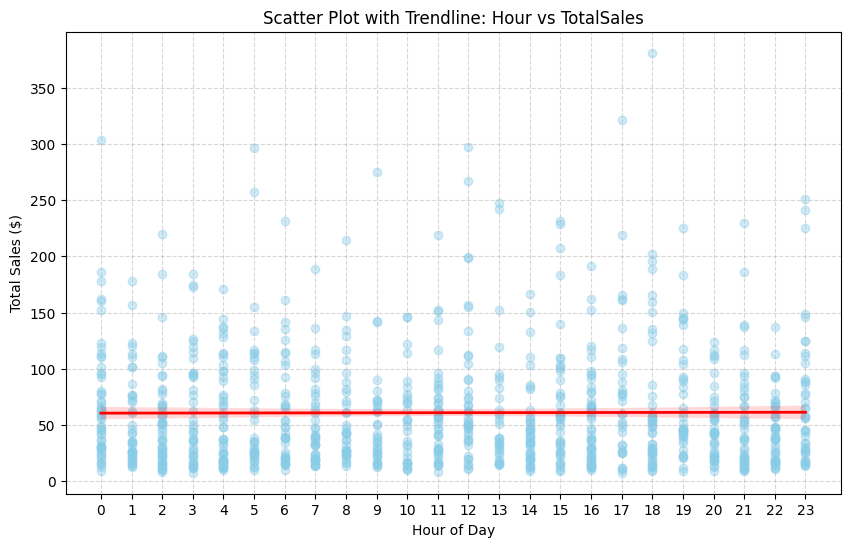

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate Pearson and Spearman correlations
pearson_corr, pearson_p = stats.pearsonr(df['Hour'], df['TotalSales'])
spearman_corr, spearman_p = stats.spearmanr(df['Hour'], df['TotalSales'])

print("--- Correlation Analysis: Hour vs TotalSales ---")
print(f"Pearson Correlation Coefficient: {pearson_corr:.5f} (p-value: {pearson_p:.4f})")
print(f"Spearman Rank Correlation:       {spearman_corr:.5f} (p-value: {spearman_p:.4f})")

# Create a visualization showing the trend across hours
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Hour', y='TotalSales', scatter_kws={'alpha':0.4, 'color': 'skyblue'}, line_kws={'color':'red', 'linewidth': 2})
plt.title('Scatter Plot with Trendline: Hour vs TotalSales')
plt.xlabel('Hour of Day')
plt.ylabel('Total Sales ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, 24))
plt.show()

--- Volume & Revenue Comparison ---
Hour  0:00 -> Total Transactions: 53, Cumulative Sales: $3747.87
Hour 12:00 -> Total Transactions: 42, Cumulative Sales: $3262.96



/tmp/ipykernel_3924/3833532163.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='Hour', y='TotalSales', palette='Set2')


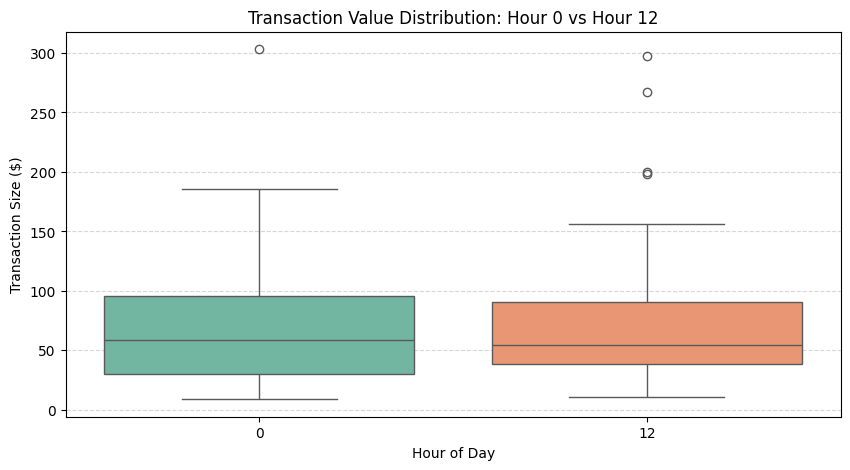

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract volume metrics from the previously generated 'hourly_ratio' and 'hourly_sales'
volume_0 = total_counts[total_counts['Hour'] == 0]['Total_Count'].values[0]
volume_12 = total_counts[total_counts['Hour'] == 12]['Total_Count'].values[0]

sales_0 = hourly_sales[hourly_sales['Hour'] == 0]['TotalSales'].values[0]
sales_12 = hourly_sales[hourly_sales['Hour'] == 12]['TotalSales'].values[0]

print("--- Volume & Revenue Comparison ---")
print(f"Hour  0:00 -> Total Transactions: {volume_0}, Cumulative Sales: ${sales_0:.2f}")
print(f"Hour 12:00 -> Total Transactions: {volume_12}, Cumulative Sales: ${sales_12:.2f}\n")

# Filter df for visualization
df_filtered = df[df['Hour'].isin([0, 12])]

# Create side-by-side box/violin plots to compare individual transaction amounts
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_filtered, x='Hour', y='TotalSales', palette='Set2')
plt.title('Transaction Value Distribution: Hour 0 vs Hour 12')
plt.xlabel('Hour of Day')
plt.ylabel('Transaction Size ($)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

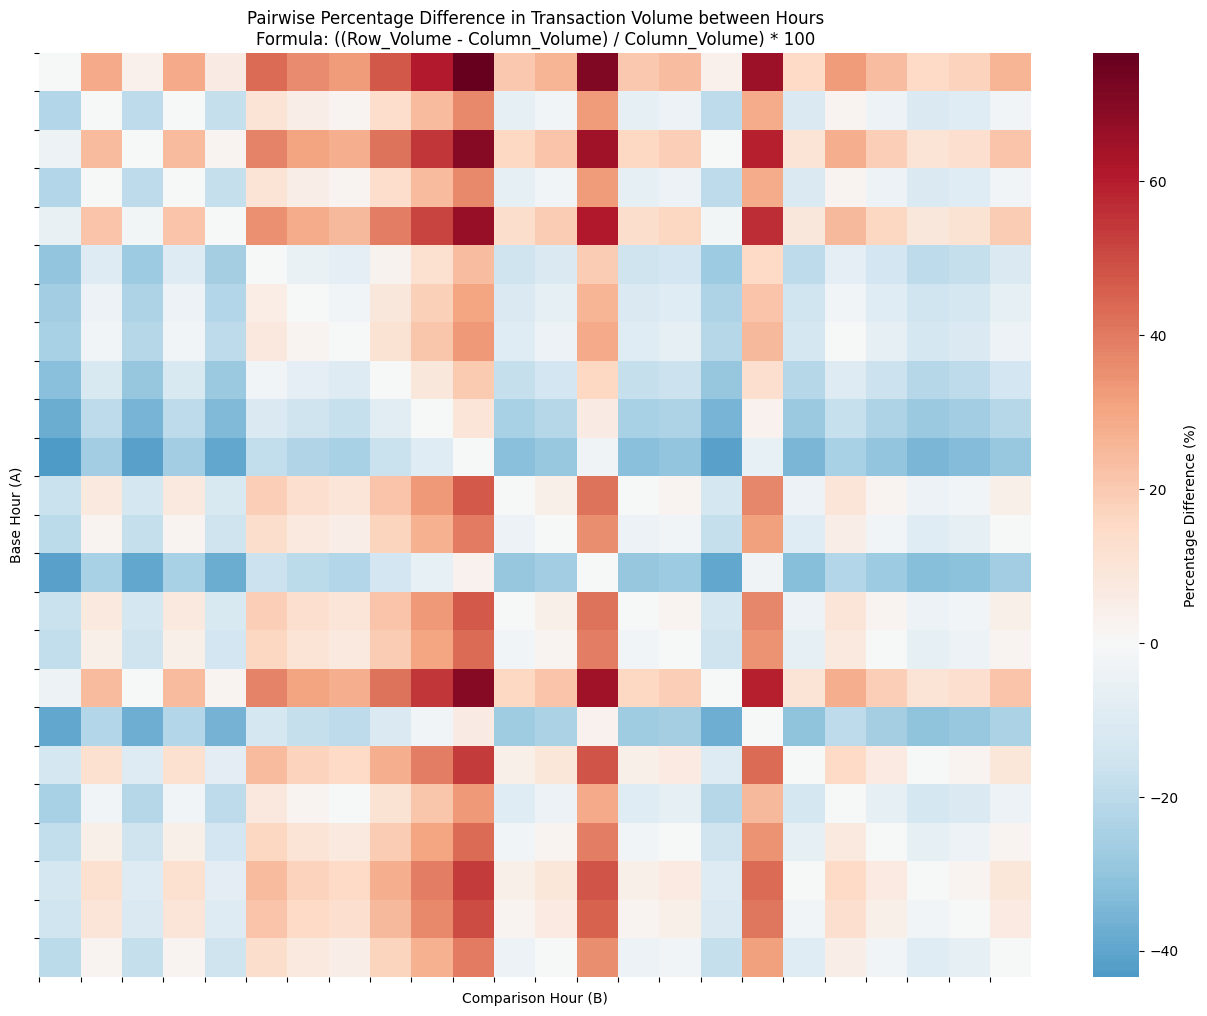


--- Top 10 Largest Volume Increases between Hours ---


,Hour A,Hour B,Volume A,Volume B,Pct_Difference
0,0,10,53,30,76.666667
1,0,13,53,31,70.967742
2,2,10,51,30,70.000000
3,16,10,51,30,70.000000
4,4,10,50,30,66.666667
5,0,17,53,32,65.625000
6,2,13,51,31,64.516129
7,16,13,51,31,64.516129
8,4,13,50,31,61.290323
9,0,9,53,33,60.606061


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Get the transaction volume (Total_Count) for each hour (0 to 23)
hourly_volumes = total_counts.set_index('Hour')['Total_Count']

# Initialize an empty 24x24 DataFrame to store the pairwise percentage differences
pct_diff_matrix = pd.DataFrame(index=range(24), columns=range(24))

# Calculate pairwise percentage differences:
# Formula: ((Volume_A - Volume_B) / Volume_B) * 100
for i in range(24):
    for j in range(24):
        vol_i = hourly_volumes.loc[i]
        vol_j = hourly_volumes.loc[j]
        if vol_j != 0:
            pct_diff_matrix.iloc[i, j] = ((vol_i - vol_j) / vol_j) * 100
        else:
            pct_diff_matrix.iloc[i, j] = np.nan

pct_diff_matrix = pct_diff_matrix.astype(float)

# Plot a heatmap of the percentage differences
plt.figure(figsize=(16, 12))
sns.heatmap(
    pct_diff_matrix,
    cmap='RdBu_r',
    center=0,
    annot=False,
    fmt=".1f",
    cbar_kws={'label': 'Percentage Difference (%)'}
)
plt.title('Pairwise Percentage Difference in Transaction Volume between Hours\nFormula: ((Row_Volume - Column_Volume) / Column_Volume) * 100')
plt.xlabel('Comparison Hour (B)')
plt.ylabel('Base Hour (A)')
plt.xticks(range(24))
plt.yticks(range(24))
plt.show()

# Display top 10 largest positive percentage differences between hours for summary insights
diffs = []
for i in range(24):
    for j in range(24):
        if i != j:
            diffs.append({
                'Hour A': i,
                'Hour B': j,
                'Volume A': hourly_volumes.loc[i],
                'Volume B': hourly_volumes.loc[j],
                'Pct_Difference': pct_diff_matrix.iloc[i, j]
            })

diffs_df = pd.DataFrame(diffs).sort_values(by='Pct_Difference', ascending=False)
print("\n--- Top 10 Largest Volume Increases between Hours ---")
display(diffs_df.head(10).reset_index(drop=True))

In [ ]:
# Identify the top 3 hours with the lowest transaction volume
lowest_3_hours = total_counts.sort_values(by='Total_Count', ascending=True).head(3)

print("--- Top 3 Hours with the Lowest Transaction Volume ---")
for index, row in lowest_3_hours.iterrows():
    print(f"Hour {int(row['Hour'])}:00 -> {int(row['Total_Count'])} transactions")

--- Top 3 Hours with the Lowest Transaction Volume ---
Hour 10:00 -> 30 transactions
Hour 13:00 -> 31 transactions
Hour 17:00 -> 32 transactions


--- Top 5 Hours with Highest Average Transaction Value ---


,Hour,Average_Sales
0,17,80.876557
1,12,77.689457
2,23,72.544465
3,19,71.516192
4,0,70.714489



--- Bottom 5 Hours with Lowest Average Transaction Value ---


,Hour,Average_Sales
0,22,46.369268
1,14,48.114470
2,20,49.796971
3,7,52.325101
4,2,53.308763


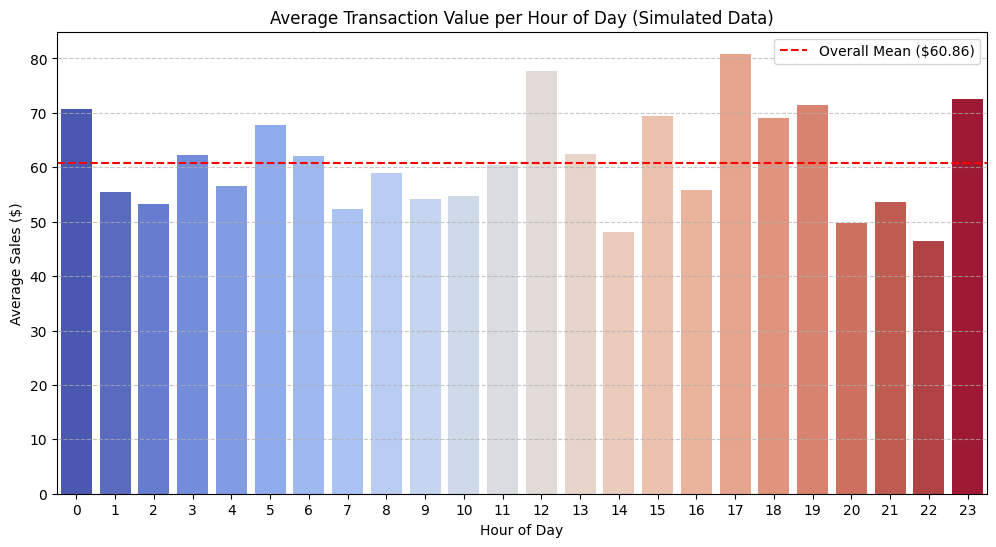

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate the average transaction value per hour
hourly_avg_sales = df.groupby('Hour')['TotalSales'].mean().reset_index(name='Average_Sales')

# Display the top 5 and bottom 5 hours by average transaction value
print("--- Top 5 Hours with Highest Average Transaction Value ---")
display(hourly_avg_sales.sort_values(by='Average_Sales', ascending=False).head(5).reset_index(drop=True))

print("\n--- Bottom 5 Hours with Lowest Average Transaction Value ---")
display(hourly_avg_sales.sort_values(by='Average_Sales', ascending=True).head(5).reset_index(drop=True))

# Visualize the average transaction value per hour
plt.figure(figsize=(12, 6))
sns.barplot(data=hourly_avg_sales, x='Hour', y='Average_Sales', hue='Hour', palette='coolwarm', legend=False)
plt.axhline(df['TotalSales'].mean(), color='red', linestyle='--', label=f"Overall Mean (${df['TotalSales'].mean():.2f})")
plt.title('Average Transaction Value per Hour of Day (Simulated Data)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Sales ($)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()